

**Aim:** Implement a simple multi-agent task allocation system using **Partial Global Planning (PGP)** and **Contract Net Protocol (CNP)**.

### Exercises covered
1. Manager Agent + 3 Delivery Agents + 6 tasks
2. PGP local planning and conflict resolution
3. CNP: announcement → bidding → comparison → selection → assignment
4. Automatic allocation of all tasks and total cost
5. Modify costs, rerun, compare, and visualize results

In [1]:
import matplotlib.pyplot as plt

class DeliveryAgent:
    def __init__(self, name, costs):
        self.name = name
        self.costs = costs
        self.plan = []

    def bid(self, task):
        return self.costs[task]

class ManagerAgent:
    def __init__(self, agents):
        self.agents = agents

    def cnp_allocate(self, tasks):
        allocation = {}
        print("CNP: Task Announcement -> Bidding -> Bid Comparison -> Selection -> Assignment\n")
        for task in tasks:
            bids = {a.name: a.bid(task) for a in self.agents}
            selected = min(bids, key=bids.get)
            allocation[task] = (selected, bids[selected])
            print(f"{task}: bids={bids} -> {selected} ({bids[selected]})")
        return allocation

In [2]:
# 1. Agent Setup
tasks = ["T1", "T2", "T3", "T4", "T5", "T6"]

agent1 = DeliveryAgent("Agent A", {"T1": 8, "T2": 5, "T3": 9, "T4": 6, "T5": 7, "T6": 8})
agent2 = DeliveryAgent("Agent B", {"T1": 6, "T2": 7, "T3": 5, "T4": 8, "T5": 6, "T6": 7})
agent3 = DeliveryAgent("Agent C", {"T1": 7, "T2": 6, "T3": 8, "T4": 5, "T5": 4, "T6": 6})

agents = [agent1, agent2, agent3]
manager = ManagerAgent(agents)

print("Manager Agent + 3 Delivery Agents")
print("Tasks:", tasks)

Manager Agent + 3 Delivery Agents
Tasks: ['T1', 'T2', 'T3', 'T4', 'T5', 'T6']


## 2. PGP Coordination

Each agent first creates a local plan. A conflict is deliberately introduced: **Agent A and Agent B both use Location L1 at time 10**. The manager detects the conflict and changes Agent B's time to 11.

In [3]:
# Local plans
agent1.plan = [("T1", "L1", 10), ("T2", "L2", 12)]
agent2.plan = [("T3", "L1", 10), ("T4", "L3", 13)]
agent3.plan = [("T5", "L4", 10), ("T6", "L5", 14)]

def find_conflicts(agents):
    seen = {}
    conflicts = []
    for agent in agents:
        for task, location, time in agent.plan:
            key = (location, time)
            if key in seen:
                conflicts.append((seen[key], (agent.name, task, location, time)))
            else:
                seen[key] = (agent.name, task, location, time)
    return conflicts

print("Before PGP:")
for a in agents:
    print(a.name, a.plan)

conflicts = find_conflicts(agents)
print("\nDetected conflicts:", conflicts)

# Partial Global Planning: modify one conflicting local plan
if conflicts:
    agent2.plan[0] = ("T3", "L1", 11)

print("\nAfter PGP conflict resolution:")
for a in agents:
    print(a.name, a.plan)

print("Remaining conflicts:", find_conflicts(agents))

Before PGP:
Agent A [('T1', 'L1', 10), ('T2', 'L2', 12)]
Agent B [('T3', 'L1', 10), ('T4', 'L3', 13)]
Agent C [('T5', 'L4', 10), ('T6', 'L5', 14)]

Detected conflicts: [(('Agent A', 'T1', 'L1', 10), ('Agent B', 'T3', 'L1', 10))]

After PGP conflict resolution:
Agent A [('T1', 'L1', 10), ('T2', 'L2', 12)]
Agent B [('T3', 'L1', 11), ('T4', 'L3', 13)]
Agent C [('T5', 'L4', 10), ('T6', 'L5', 14)]
Remaining conflicts: []


## 3 & 4. CNP Task Allocation

For every task, the manager announces the task. Each agent submits a bid based on its cost. The manager selects the lowest bid and assigns the task.

In [4]:
allocation1 = manager.cnp_allocate(tasks)

print("\nFinal Allocation")
print("-" * 35)
print("Task | Selected Agent | Cost/Time")
print("-" * 35)

for task, (agent, cost) in allocation1.items():
    print(f"{task:4} | {agent:14} | {cost}")

total1 = sum(cost for _, cost in allocation1.values())
print("-" * 35)
print("Total Cost/Time:", total1)

CNP: Task Announcement -> Bidding -> Bid Comparison -> Selection -> Assignment

T1: bids={'Agent A': 8, 'Agent B': 6, 'Agent C': 7} -> Agent B (6)
T2: bids={'Agent A': 5, 'Agent B': 7, 'Agent C': 6} -> Agent A (5)
T3: bids={'Agent A': 9, 'Agent B': 5, 'Agent C': 8} -> Agent B (5)
T4: bids={'Agent A': 6, 'Agent B': 8, 'Agent C': 5} -> Agent C (5)
T5: bids={'Agent A': 7, 'Agent B': 6, 'Agent C': 4} -> Agent C (4)
T6: bids={'Agent A': 8, 'Agent B': 7, 'Agent C': 6} -> Agent C (6)

Final Allocation
-----------------------------------
Task | Selected Agent | Cost/Time
-----------------------------------
T1   | Agent B        | 6
T2   | Agent A        | 5
T3   | Agent B        | 5
T4   | Agent C        | 5
T5   | Agent C        | 4
T6   | Agent C        | 6
-----------------------------------
Total Cost/Time: 31


Agent-wise total cost: {'Agent A': 5, 'Agent B': 11, 'Agent C': 15}


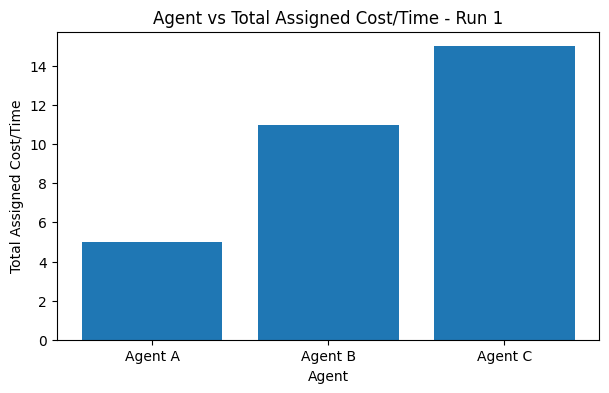

In [5]:
# Convert allocation into agent-wise totals
def agent_totals(allocation):
    totals = {a.name: 0 for a in agents}
    for _, (agent, cost) in allocation.items():
        totals[agent] += cost
    return totals

totals1 = agent_totals(allocation1)
print("Agent-wise total cost:", totals1)

plt.figure(figsize=(7, 4))
plt.bar(totals1.keys(), totals1.values())
plt.xlabel("Agent")
plt.ylabel("Total Assigned Cost/Time")
plt.title("Agent vs Total Assigned Cost/Time - Run 1")
plt.show()

## 5. Modify Costs and Run Again

Some task costs are changed to simulate a new environment. The CNP is executed again and the two allocations are compared.

In [6]:
# Modified costs
agent1.costs.update({"T3": 3, "T5": 9})
agent2.costs.update({"T1": 4, "T6": 3})
agent3.costs.update({"T2": 3, "T4": 2})

allocation2 = manager.cnp_allocate(tasks)

print("\nFinal Allocation - Run 2")
print("-" * 35)
print("Task | Selected Agent | Cost/Time")
print("-" * 35)

for task, (agent, cost) in allocation2.items():
    print(f"{task:4} | {agent:14} | {cost}")

total2 = sum(cost for _, cost in allocation2.values())
print("-" * 35)
print("Total Cost/Time:", total2)

totals2 = agent_totals(allocation2)
print("Agent-wise total cost:", totals2)

CNP: Task Announcement -> Bidding -> Bid Comparison -> Selection -> Assignment

T1: bids={'Agent A': 8, 'Agent B': 4, 'Agent C': 7} -> Agent B (4)
T2: bids={'Agent A': 5, 'Agent B': 7, 'Agent C': 3} -> Agent C (3)
T3: bids={'Agent A': 3, 'Agent B': 5, 'Agent C': 8} -> Agent A (3)
T4: bids={'Agent A': 6, 'Agent B': 8, 'Agent C': 2} -> Agent C (2)
T5: bids={'Agent A': 9, 'Agent B': 6, 'Agent C': 4} -> Agent C (4)
T6: bids={'Agent A': 8, 'Agent B': 3, 'Agent C': 6} -> Agent B (3)

Final Allocation - Run 2
-----------------------------------
Task | Selected Agent | Cost/Time
-----------------------------------
T1   | Agent B        | 4
T2   | Agent C        | 3
T3   | Agent A        | 3
T4   | Agent C        | 2
T5   | Agent C        | 4
T6   | Agent B        | 3
-----------------------------------
Total Cost/Time: 19
Agent-wise total cost: {'Agent A': 3, 'Agent B': 7, 'Agent C': 9}


Comparison
T1: Agent B (6) -> Agent B (4)
T2: Agent A (5) -> Agent C (3)
T3: Agent B (5) -> Agent A (3)
T4: Agent C (5) -> Agent C (2)
T5: Agent C (4) -> Agent C (4)
T6: Agent C (6) -> Agent B (3)


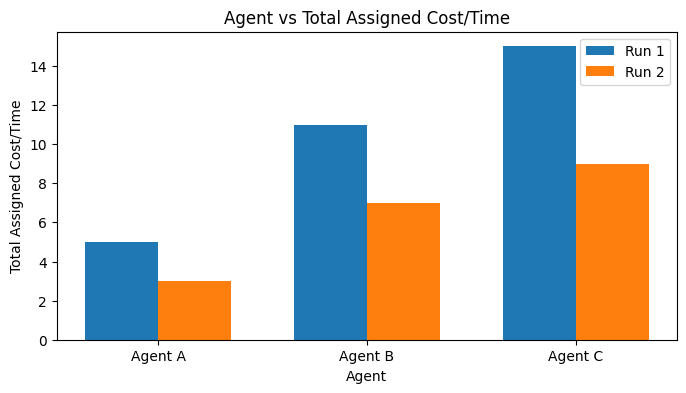

In [7]:
# Compare Run 1 and Run 2
print("Comparison")
for task in tasks:
    a1, c1 = allocation1[task]
    a2, c2 = allocation2[task]
    print(f"{task}: {a1} ({c1}) -> {a2} ({c2})")

x = range(len(agents))
width = 0.35

plt.figure(figsize=(8, 4))
plt.bar([i - width/2 for i in x], [totals1[a.name] for a in agents],
        width=width, label="Run 1")
plt.bar([i + width/2 for i in x], [totals2[a.name] for a in agents],
        width=width, label="Run 2")

plt.xticks(list(x), [a.name for a in agents])
plt.xlabel("Agent")
plt.ylabel("Total Assigned Cost/Time")
plt.title("Agent vs Total Assigned Cost/Time")
plt.legend()
plt.show()

## Observation

- **PGP** detects the shared-resource conflict and changes one agent's local plan.
- **CNP** announces each task, collects bids, compares them, and assigns the task to the lowest-cost agent.
- All six tasks are allocated automatically.
- Changing agent/task costs changes the selected agents and the total cost/time.
- The bar chart makes the difference between the two runs easy to compare.